In [ ]:
Здесь у нас просто графики для давлений для подопытных

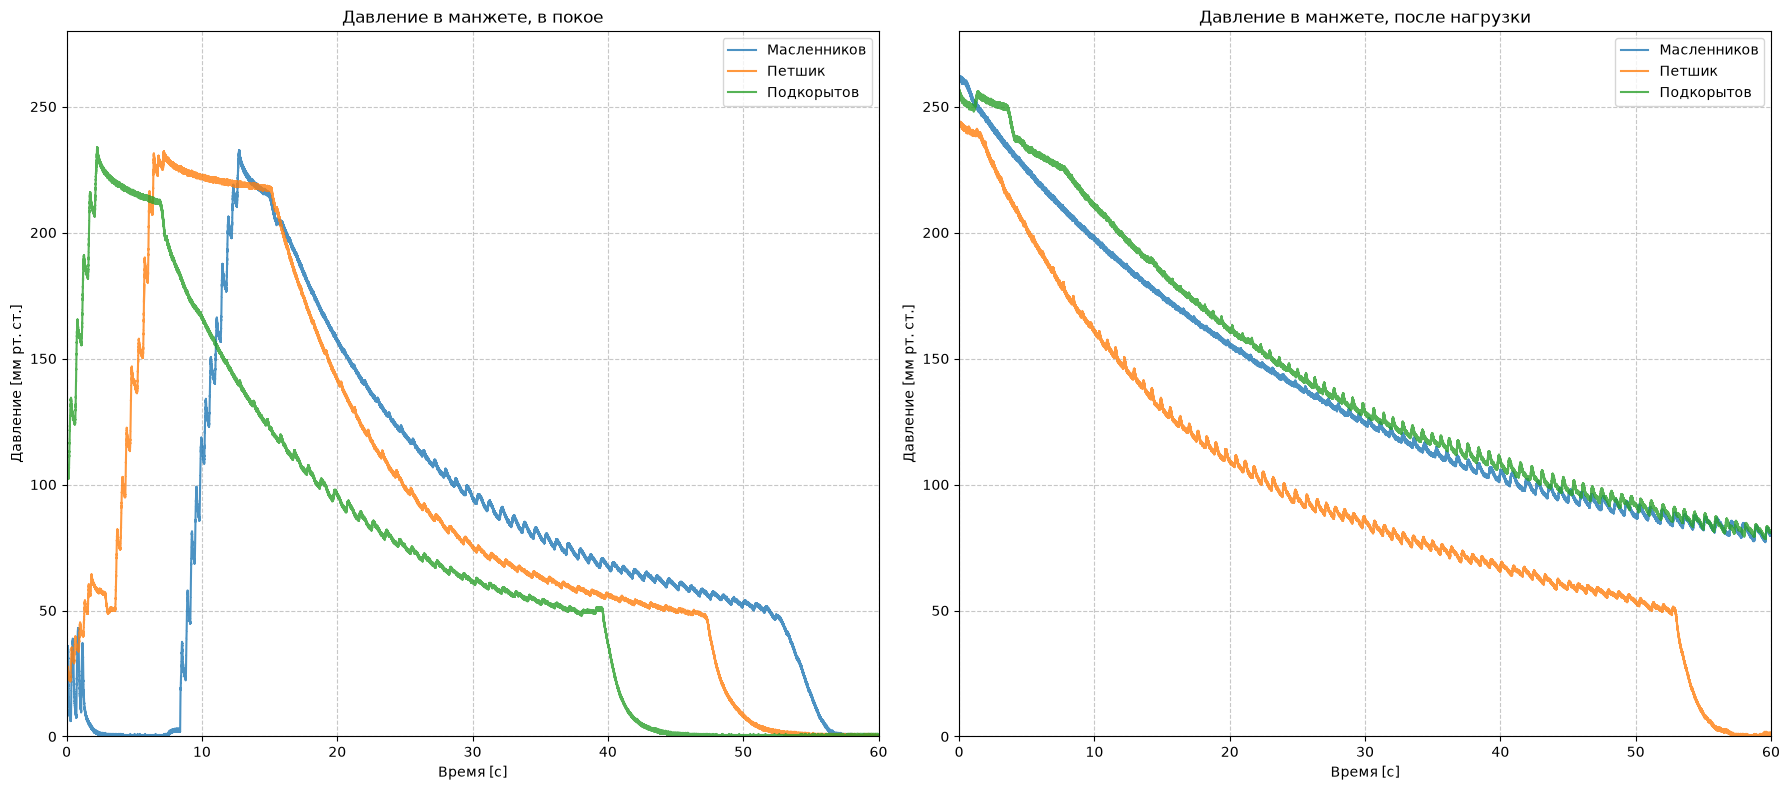

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import os

data_folder = '../5.3. Resting and post-exercise blood pressure'
files = ['rest_Mas.csv', 'rest_Pet.csv', 'rest_Pod.csv', 'fitness_Mas.csv', 'fitness_Pet.csv', 'fitness_Pod.csv']

names_map = {
    'Mas': 'Масленников',
    'Pet': 'Петшик',
    'Pod': 'Подкорытов'
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

for f in files:
    filepath = os.path.join(data_folder, f)
    
    if not os.path.exists(filepath):
        continue
        
    df = pd.read_csv(filepath)
    t = df.iloc[:, 0].values
    p = df.iloc[:, 1].values

    code = f.split('_')[1].split('.')[0]
    label_name = names_map.get(code, f)

    if 'rest' in f:
        ax1.plot(t, p, label=label_name, alpha=0.8)
    elif 'fitness' in f:
        ax2.plot(t, p, label=label_name, alpha=0.8)

ax1.set_title('Давление в манжете, в покое')
ax1.set_xlabel('Время [с]')
ax1.set_ylabel('Давление [мм рт. ст.]')
ax1.set_xlim(0, 60)
ax1.set_ylim(0, 280)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.set_title('Давление в манжете, после нагрузки')
ax2.set_xlabel('Время [с]')
ax2.set_ylabel('Давление [мм рт. ст.]')
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 280)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('pressure_plots.png', bbox_inches='tight')
plt.show()


In [ ]:
Калибровка датчика

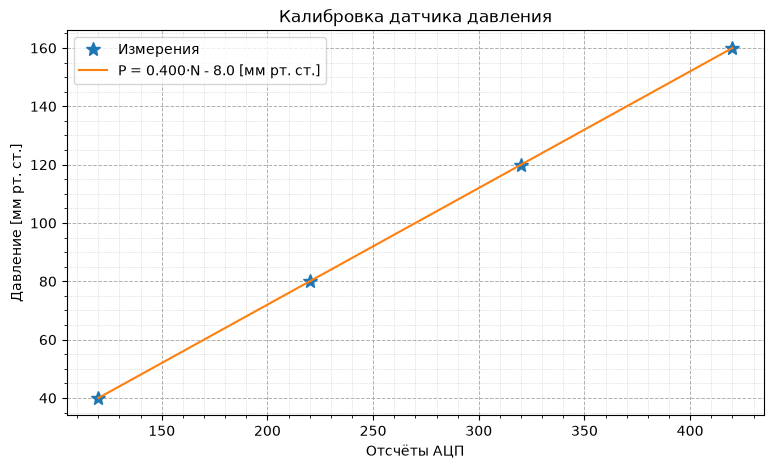

In [2]:
import matplotlib.pyplot as plt
import numpy as np


N = np.array([120, 220, 320, 420])  
P = np.array([40, 80, 120, 160])   


coeffs = np.polyfit(N, P, 1)
k = coeffs[0]
b = coeffs[1]


sign = "+" if b >= 0 else "-"
eq_text = f"P = {k:.3f}·N {sign} {abs(b):.1f} [мм рт. ст.]"


plt.figure(figsize=(9, 5))


plt.plot(N, P, '*', color='#1f77b4', markersize=10, label='Измерения')
plt.plot(N, np.polyval(coeffs, N), '-', color='#ff7f0e', label=eq_text)


plt.title("Калибровка датчика давления")
plt.xlabel("Отсчёты АЦП")
plt.ylabel("Давление [мм рт. ст.]")


plt.grid(True, which='major', linestyle='--', linewidth=0.7)
plt.minorticks_on()
plt.grid(True, which='minor', linestyle=':', linewidth=0.5, alpha=0.7)

plt.legend(loc='upper left')

plt.show()

In [ ]:
Здесь у нас графики с систолическим и диастолсическим давлением

Масленников (спокойный): пороги 60%/75% -> 112/72


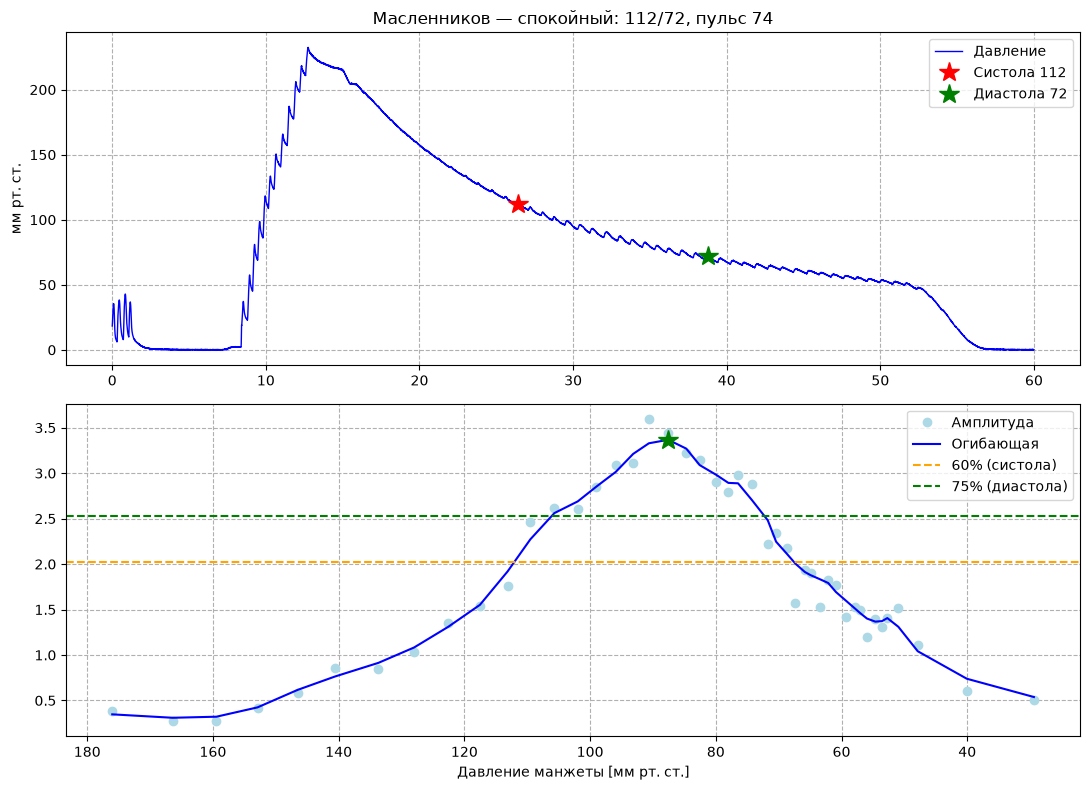

Масленников (физ. нагрузка): пороги 60%/75% -> 125/83


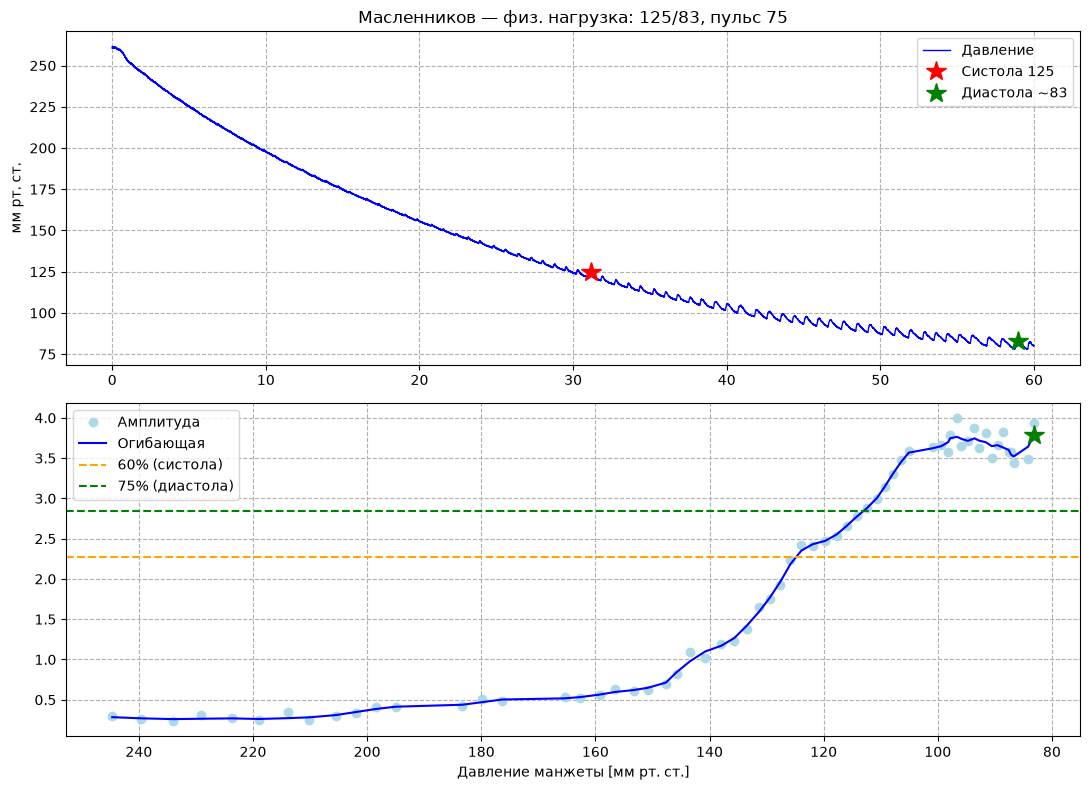

Петшик (спокойный): пороги 85%/85% (шум-порог Петшик) -> 134/74


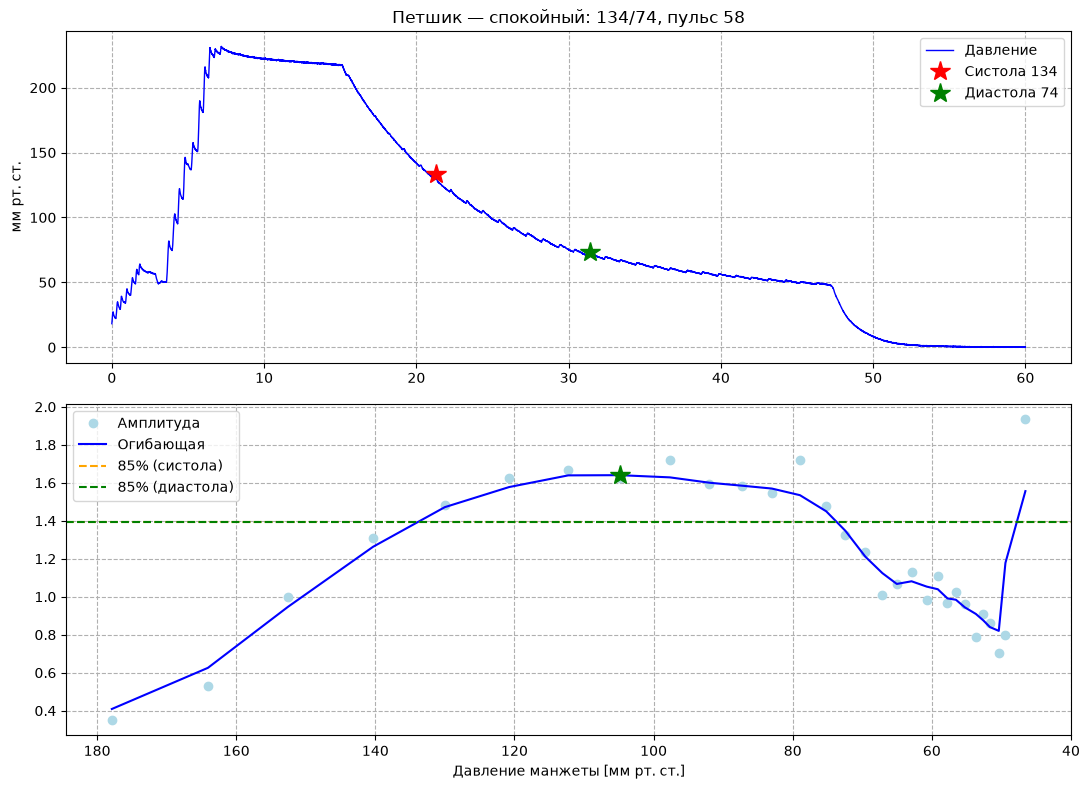

Петшик (физ. нагрузка): пороги 60%/75% -> 157/90


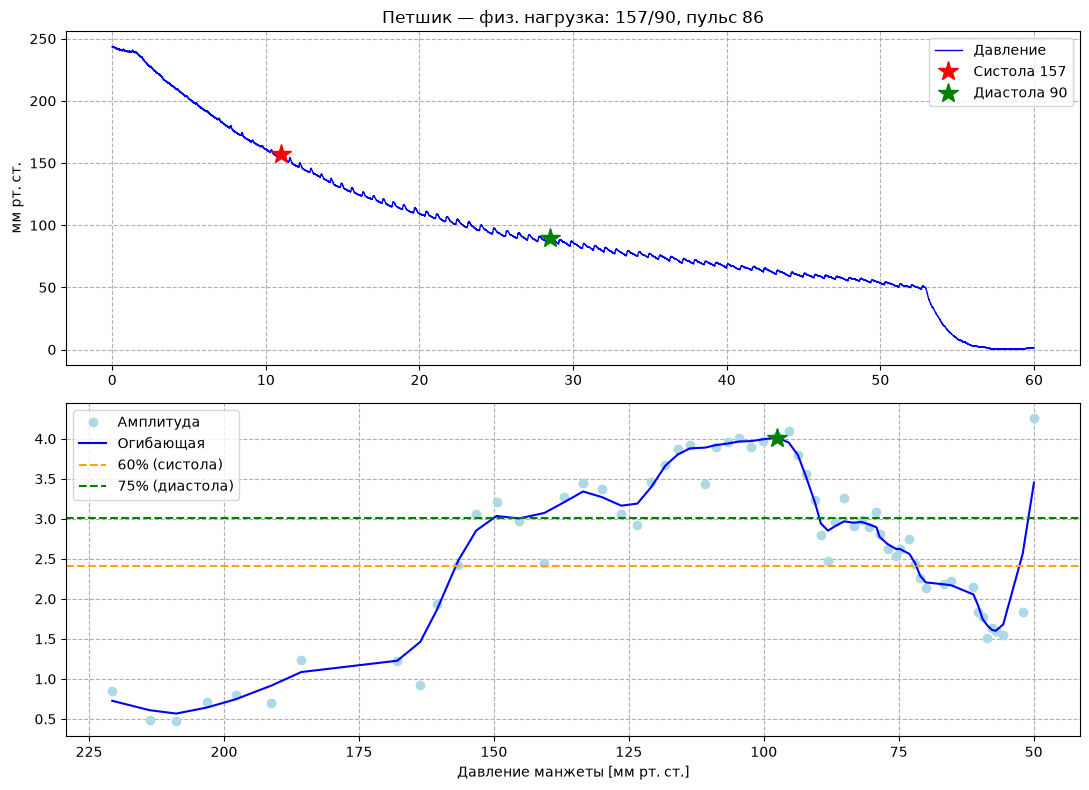

Подкорытов (спокойный): пороги 60%/75% -> 129/80


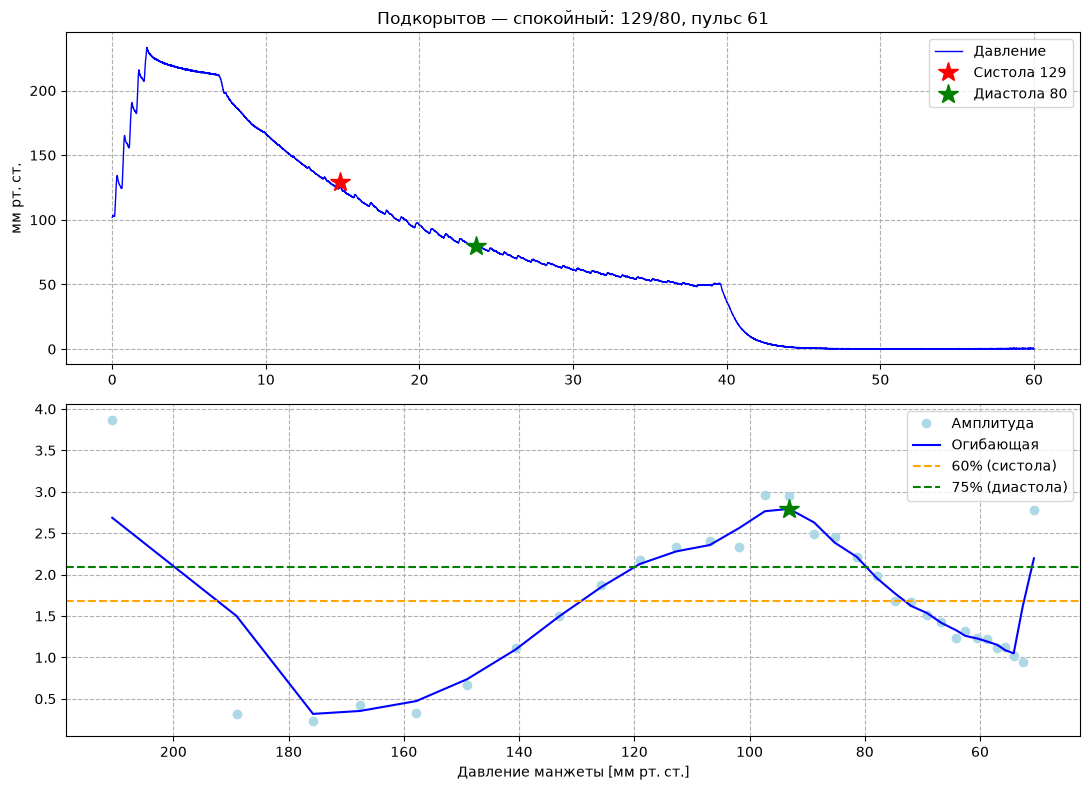

Подкорытов (физ. нагрузка): пороги 60%/75% -> 142/85


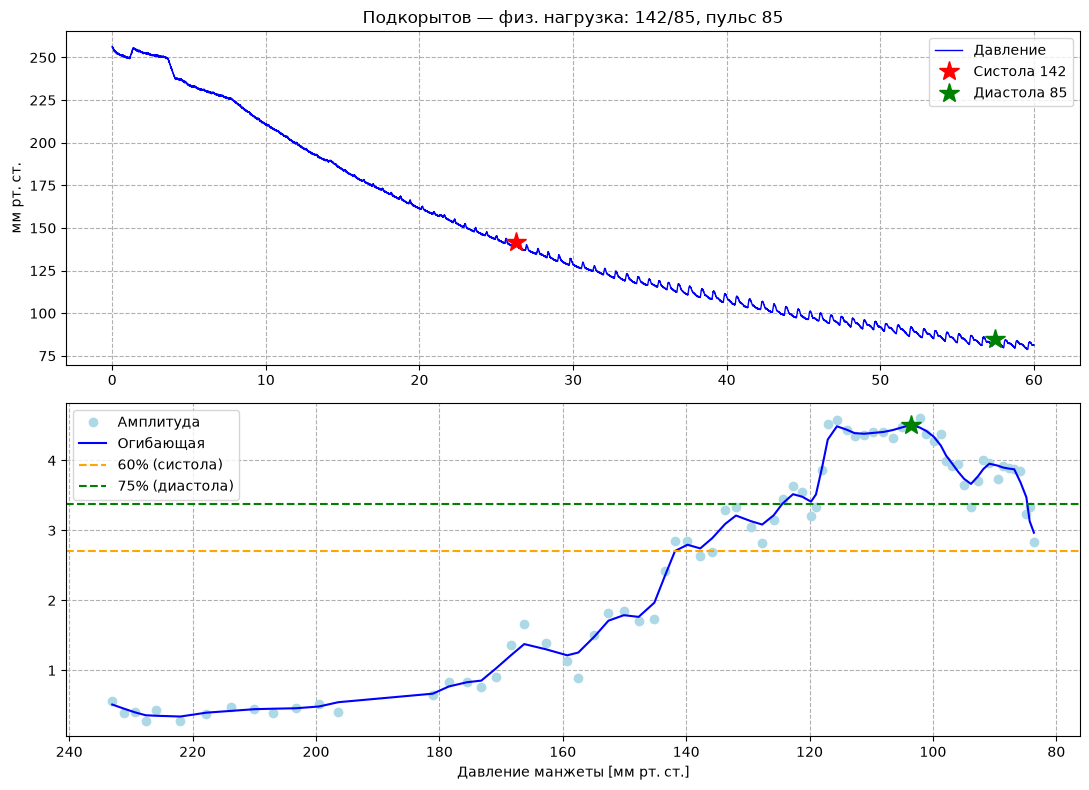


     subject          cond     pulse        sbp       dbp           mode        map   dbp_1_3
Масленников     спокойный 73.877978 112.089592 72.230697          порог  87.567425 75.306342
Масленников физ. нагрузка 75.084470 124.780223 83.157950 макс.амплитуда  83.157950 62.346813
     Петшик     спокойный 57.959815 133.851698 73.690416          порог 104.886475 90.403864
     Петшик физ. нагрузка 85.812357 157.060592 89.706637          порог  97.501900 67.722554
 Подкорытов     спокойный 61.155845 129.307915 79.788525          порог  93.145650 75.064517
 Подкорытов физ. нагрузка 85.070183 141.814523 84.714234          порог 103.558250 84.430114


In [16]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d, median_filter

DATA_DIR = '.'
FILES = {
    'Масленников': {'rest': 'rest_Mas.csv', 'fitness': 'fitness_Mas.csv'},
    'Петшик': {'rest': 'rest_Pet.csv', 'fitness': 'fitness_Pet.csv'},
    'Подкорытов': {'rest': 'rest_Pod.csv', 'fitness': 'fitness_Pod.csv'},
}
COND_NAMES = {'rest': 'спокойный', 'fitness': 'физ. нагрузка'}
K_SYS, K_DIA = 0.60, 0.75
RATIOS = {('Петшик', 'rest'): (0.85, 0.85)}
FS_NEW = 200
TREND_WIN = 1.5

def load(path):
    txt = open(path, encoding='utf-8', errors='ignore').read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:,0].to_numpy(float), df.iloc[:,1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p); t, p = t[ok], p[ok]
    o = np.argsort(t); t, p = t[o], p[o]; t = t - t[0]
    if p.max() < 10: p = 83.66*p - 11.33
    return t, p

def downsample(t, p, fs_new=FS_NEW):
    fs = 1.0/np.median(np.diff(t))
    k = max(1, int(round(fs/fs_new)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], fs/k

def detrend(p, fs):
    trend = uniform_filter1d(p, size=max(1, int(fs*TREND_WIN)), mode='nearest')
    return p - trend

def deflation_bounds(p, fs):
    sm = uniform_filter1d(p, int(fs*0.5), mode='nearest')
    M = sm.max()
    plat = np.where(sm >= M-3)[0]
    i0 = plat[-1] if len(plat) else int(np.argmax(sm))
    after = np.where(sm[i0:] < M-6)[0]
    if len(after): i0 += after[0]
    below = np.where(sm[i0:] < 20)[0]
    i1 = i0 + below[0] if len(below) else len(p)-1
    return i0, i1, len(below) == 0, M

def envelope(td, pd_, osc, fs, M):
    peaks,_ = find_peaks(osc, distance=int(0.35*fs), prominence=0.2)
    win = int(0.30*fs)
    tb, pb, amp = [], [], []
    for pk in peaks:
        a, b = max(0,pk-win), min(len(osc),pk+win)
        if pk-a < 5 or b-pk < 5: continue
        base = 0.5*(osc[a:pk].min() + osc[pk:b].min())
        tb.append(td[pk]); pb.append(pd_[pk]); amp.append(osc[pk]-base)
    tb, pb, amp = map(np.array, (tb, pb, amp))
    if len(amp) < 10: return None
    m = (tb > td[0]+1.0) & (pb < M-15) & (tb < td[-1]-0.5)
    tb, pb, amp = tb[m], pb[m], amp[m]
    rr = np.diff(tb); med = np.median(rr)
    good = np.ones(len(tb), bool)
    good[1:] &= (rr > 0.75*med) & (rr < 1.25*med)
    good[:-1] &= (rr > 0.75*med) & (rr < 1.25*med)
    tb, pb, amp = tb[good], pb[good], amp[good]
    sm = uniform_filter1d(median_filter(amp, 3, mode='nearest'), 3, mode='nearest')
    return tb, pb, amp, sm

def estimate(pb, sm, k_sys, k_dia):
    im = int(np.argmax(sm)); amax = sm[im]
    thr = k_sys*amax
    start = im
    while start > 0 and sm[start-1] >= thr: start -= 1
    if start == 0:
        sbp = pb[0]
    else:
        j = start
        w = (thr-sm[j-1])/(sm[j]-sm[j-1]) if sm[j] != sm[j-1] else 0
        sbp = pb[j-1] + w*(pb[j]-pb[j-1])
    thr_d = k_dia*amax
    fall = np.where(sm[im:] <= thr_d)[0]
    if len(fall):
        j = im + fall[0]
        w = (sm[j-1]-thr_d)/(sm[j-1]-sm[j]) if j > 0 and sm[j-1] != sm[j] else 0
        dbp = pb[j-1] + w*(pb[j]-pb[j-1]) if j > 0 else pb[j]
        mode = 'порог'
    else:
        dbp = pb[im]; mode = 'макс.амплитуда'
    map_ = pb[im]
    dbp_third = (3*map_ - sbp)/2
    return dict(sbp=sbp, dbp=dbp, mode=mode, map=map_, amax=amax, im=im, dbp_third=dbp_third)

def analyze(path):
    t, p, fs = downsample(*load(path))
    i0, i1, truncated, M = deflation_bounds(p, fs)
    td, pd_ = t[i0:i1+1], p[i0:i1+1]
    osc = detrend(pd_, fs)
    env = envelope(td, pd_, osc, fs, M)
    if env is None: return None
    tb, pb, amp, sm = env
    return dict(t=t, p=p, fs=fs, tb=tb, pb=pb, amp=amp, sm=sm,
                pulse=60/np.median(np.diff(tb)), truncated=truncated)

def plot_res(name, cond_label, r, ks, kd):
    fig, ax = plt.subplots(2, 1, figsize=(11, 8))
    ax[0].plot(r['t'], r['p'], 'b-', lw=1, label='Давление')
    i = int(np.argmin(abs(r['pb']-r['sbp'])))
    ax[0].plot(r['tb'][i], r['sbp'], 'r*', ms=15, label=f"Систола {r['sbp']:.0f}")
    if r['mode'] == 'порог':
        i = int(np.argmin(abs(r['pb']-r['dbp'])))
        ax[0].plot(r['tb'][i], r['dbp'], 'g*', ms=15, label=f"Диастола {r['dbp']:.0f}")
    else:
        i = r['im']
        ax[0].plot(r['tb'][i], r['pb'][i], 'g*', ms=15, label=f"Диастола ~{r['pb'][i]:.0f}")
    ax[0].set_title(f"{name} — {cond_label}: {r['sbp']:.0f}/{r['dbp']:.0f}, пульс {r['pulse']:.0f}")
    ax[0].set_ylabel('мм рт. ст.'); ax[0].legend(); ax[0].grid(ls='--')
    ax[1].plot(r['pb'], r['amp'], 'o', color='lightblue', label='Амплитуда')
    ax[1].plot(r['pb'], r['sm'], 'b-', label='Огибающая')
    ax[1].axhline(ks*r['amax'], color='orange', ls='--', label=f'{ks:.0%} (систола)')
    ax[1].axhline(kd*r['amax'], color='green', ls='--', label=f'{kd:.0%} (диастола)')
    ax[1].plot(r['pb'][r['im']], r['sm'][r['im']], 'g*', ms=15)
    ax[1].set_xlabel('Давление манжеты [мм рт. ст.]'); ax[1].invert_xaxis()
    ax[1].legend(); ax[1].grid(ls='--')
    plt.tight_layout(); plt.show()

rows = []
for name, f in FILES.items():
    for cond in ('rest', 'fitness'):
        key = (name, cond)
        path = os.path.join(DATA_DIR, f[cond])
        if not os.path.exists(path): print('НЕТ ФАЙЛА:', path); continue
        r = analyze(path)
        if r is None: print(f'{name}: мало волн'); continue
        ks, kd = RATIOS.get(key, (K_SYS, K_DIA))
        r.update(estimate(r['pb'], r['sm'], ks, kd))
        print(f"{name} ({COND_NAMES[cond]}): {r['sbp']:.0f}/{r['dbp']:.0f}, пульс {r['pulse']:.0f}")
        rows.append(dict(subject=name, cond=COND_NAMES[cond], pulse=r['pulse'],
                         sbp=r['sbp'], dbp=r['dbp'], mode=r['mode'], map=r['map'], dbp_1_3=r['dbp_third']))
        plot_res(name, COND_NAMES[cond], r, ks, kd)
print('\n', pd.DataFrame(rows).to_string(index=False))

In [ ]:
Здесь пульсации

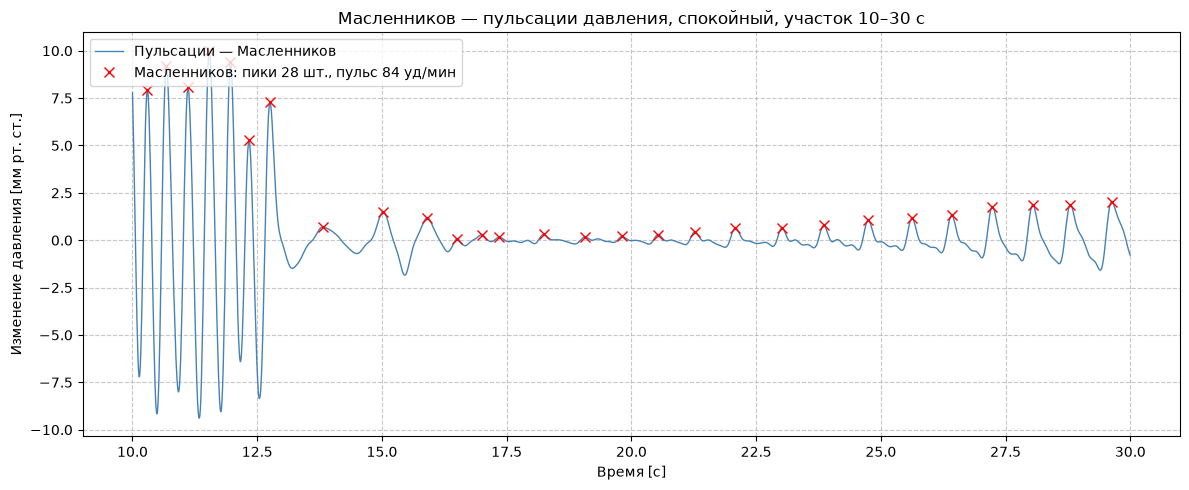

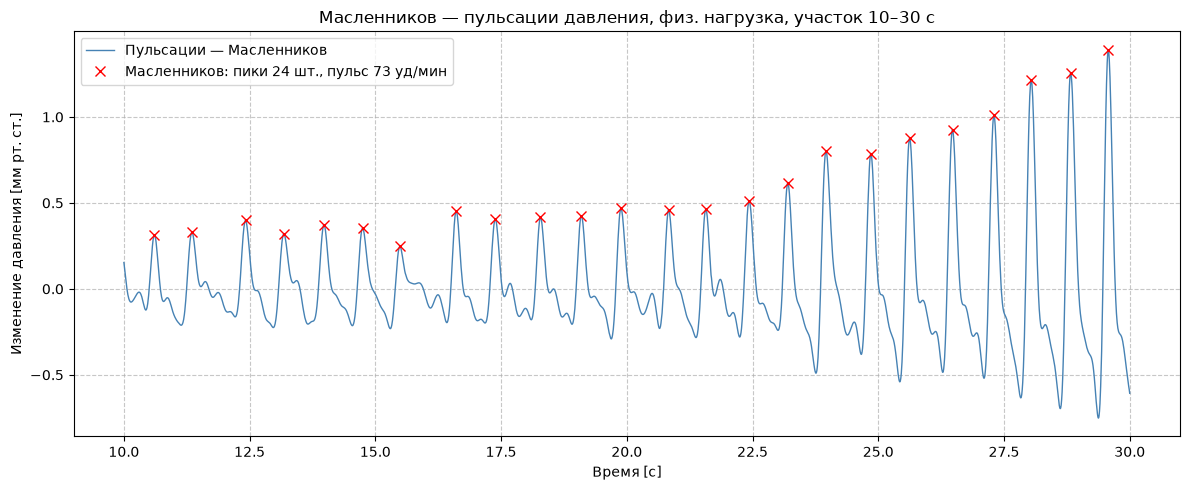

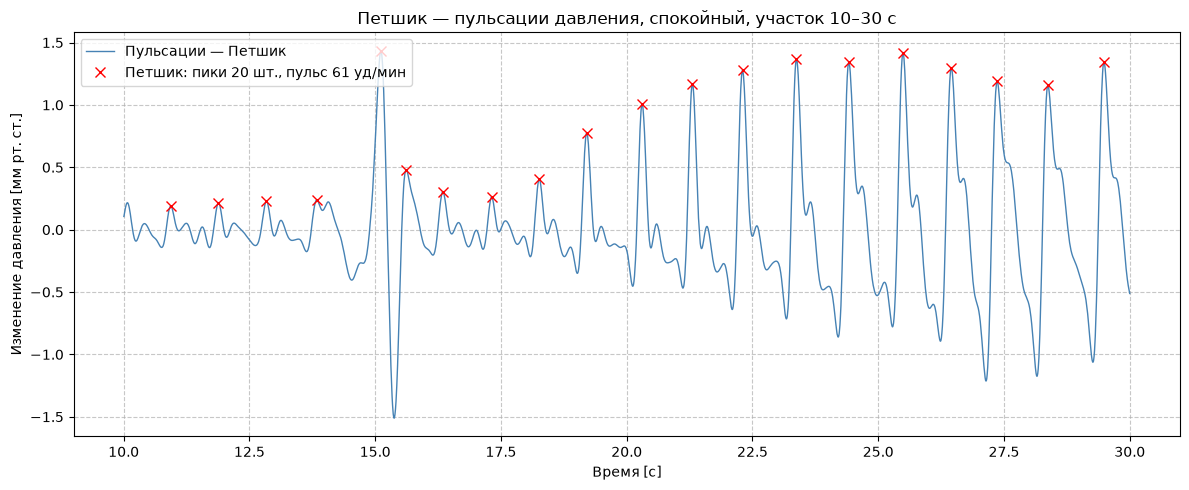

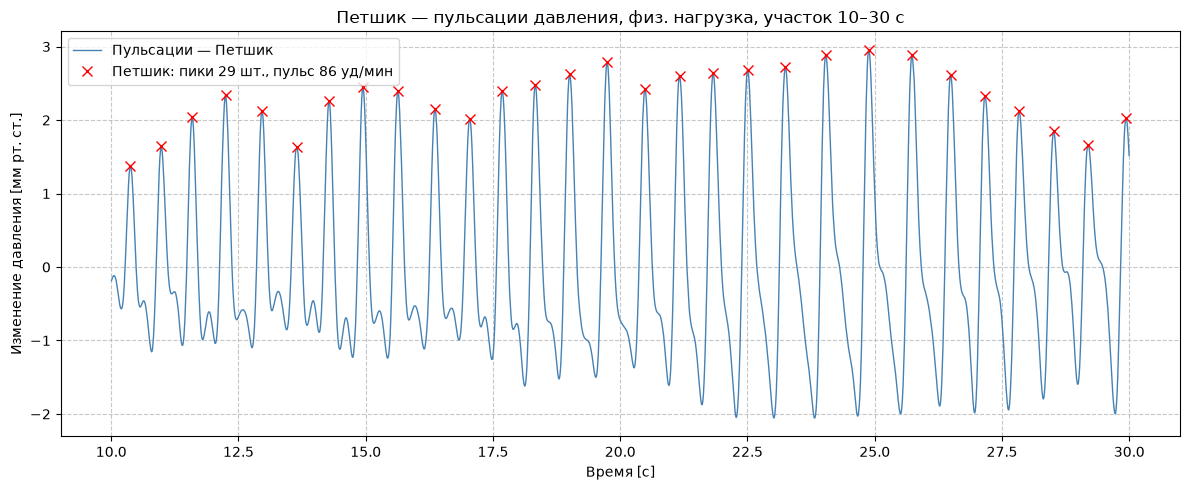

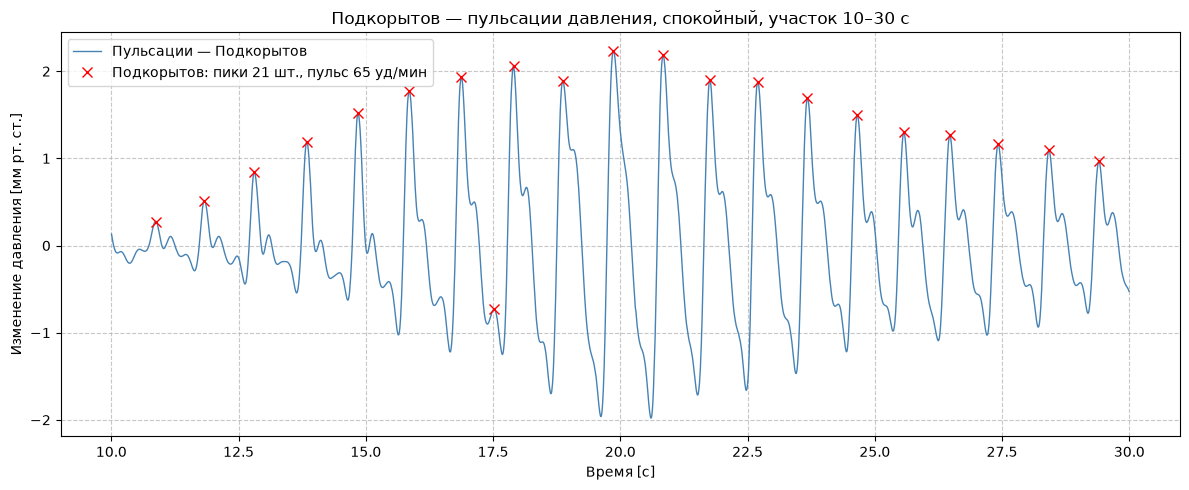

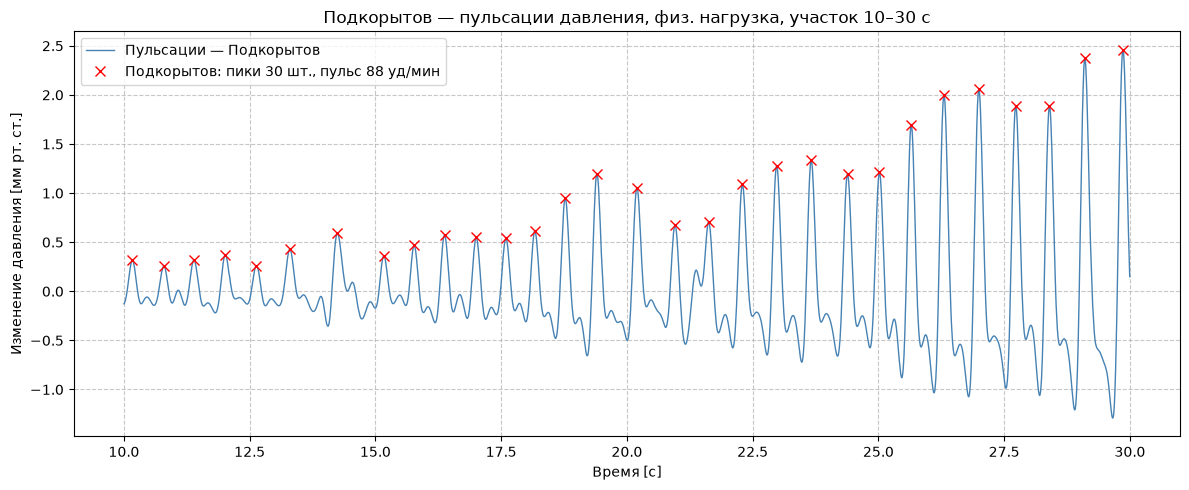


     subject          cond  peaks  pulse
Масленников     спокойный     28     84
Масленников физ. нагрузка     24     73
     Петшик     спокойный     20     61
     Петшик физ. нагрузка     29     86
 Подкорытов     спокойный     21     65
 Подкорытов физ. нагрузка     30     88


In [17]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

DATA_DIR = '.'
FILES = {
    'Масленников': {'rest': 'rest_Mas.csv', 'fitness': 'fitness_Mas.csv'},
    'Петшик': {'rest': 'rest_Pet.csv', 'fitness': 'fitness_Pet.csv'},
    'Подкорытов': {'rest': 'rest_Pod.csv', 'fitness': 'fitness_Pod.csv'},
}
WINDOW = (10.0, 30.0)
WINDOW_OVERRIDE = {}
FS_NEW = 200
TREND_WIN = 1.5

def load(path):
    txt = open(path, encoding='utf-8', errors='ignore').read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:,0].to_numpy(float), df.iloc[:,1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p); t, p = t[ok], p[ok]
    o = np.argsort(t); t, p = t[o], p[o]; t = t - t[0]
    if p.max() < 10: p = 83.66*p - 11.33
    return t, p

def downsample(t, p, fs_new=FS_NEW):
    fs = 1.0/np.median(np.diff(t))
    k = max(1, int(round(fs/fs_new)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], fs/k

def plot_pulsations(name, cond, t, p, fs):
    w0, w1 = WINDOW_OVERRIDE.get((name, cond), WINDOW)
    trend = uniform_filter1d(p, size=max(1, int(fs*TREND_WIN)), mode='nearest')
    osc = p - trend
    m = (t >= w0) & (t <= w1)
    tw, ow = t[m], osc[m]
    peaks,_ = find_peaks(ow, distance=int(0.35*fs), prominence=0.15)
    n = len(peaks)
    pulse = (n-1)*60/(tw[peaks[-1]]-tw[peaks[0]]) if n >= 2 else None
    cond_title = 'физ. нагрузка' if cond == 'fitness' else 'спокойный'
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(tw, ow, color='steelblue', lw=1.0, label=f'Пульсации — {name}')
    lbl = f'{name}: пики {n} шт., пульс {pulse:.0f} уд/мин' if pulse else f'{name}: пики {n} шт.'
    ax.plot(tw[peaks], ow[peaks], 'x', color='red', markersize=7, label=lbl)
    ax.set_title(f'{name} — пульсации давления, {cond_title}, участок {w0:.0f}–{w1:.0f} с')
    ax.set_xlabel('Время [с]')
    ax.set_ylabel('Изменение давления [мм рт. ст.]')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout(); plt.show()
    return n, pulse

rows = []
for name, f in FILES.items():
    for cond in ('rest', 'fitness'):
        path = os.path.join(DATA_DIR, f[cond])
        if not os.path.exists(path): print('НЕТ ФАЙЛА:', path); continue
        t, p, fs = downsample(*load(path))
        n, pulse = plot_pulsations(name, cond, t, p, fs)
        cond_label = 'физ. нагрузка' if cond == 'fitness' else 'спокойный'
        rows.append(dict(subject=name, cond=cond_label, peaks=n, pulse=round(pulse) if pulse else None))
print('\n', pd.DataFrame(rows).to_string(index=False))

In [ ]:
Здесь высчитываем жесткость сосудов Петшика


==================== Петшик (Покой) ====================
Субъект: Петшик | Рост: 178 см
Обработано ударов: 24
Константа спада (k): 4.299 ± 3.941 [1/с]
Постоянная времени (τ): 585.4 ± 491.6 [мс]
Интерпретация: Нормальная эластичность

==================== Петшик (Нагрузка) ====================
Субъект: Петшик | Рост: 178 см
Обработано ударов: 48
Константа спада (k): 6.414 ± 4.653 [1/с]
Постоянная времени (τ): 339.3 ± 326.7 [мс]
Интерпретация: Жесткие сосуды

СВОДКА ПО ПЕТШИКУ (Рост: 178 см)
        Состояние  Константа спада k [1/с]  Эластичность τ [мс]
   Петшик (Покой)                    4.299                232.6
Петшик (Нагрузка)                    6.414                155.9


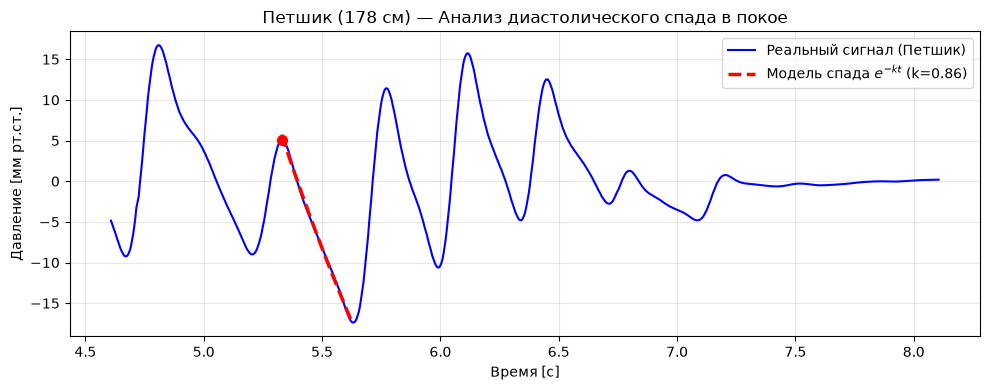

In [11]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d
from scipy.optimize import curve_fit

FILES = {
    'Петшик (Покой)': 'rest_Pet.csv',
    'Петшик (Нагрузка)': 'fitness_Pet.csv',
}
HEIGHT_CM = 178
FS_NEW = 200
TREND_WIN = 1.5

def load_data(path):
    with open(path, 'r', encoding='utf-8', errors='ignore') as f:
        txt = f.read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:,0].to_numpy(float), df.iloc[:,1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p)
    t, p = t[ok], p[ok]
    t = t - t[0]
    if p.max() < 15:
        p = 83.66 * p - 11.33
    fs = 1.0 / np.median(np.diff(t))
    k = max(1, int(round(fs / FS_NEW)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], FS_NEW

def analyze_elasticity(name, path):
    print(f"\n{'='*20} {name} {'='*20}")
    print(f"Субъект: Петшик | Рост: {HEIGHT_CM} см")
    t, p, fs = load_data(path)
    trend = uniform_filter1d(p, size=max(1, int(fs*TREND_WIN)), mode='nearest')
    p_filt = p - trend
    peaks, _ = find_peaks(p_filt, distance=int(0.4*fs), prominence=0.5)
    mins, _ = find_peaks(-p_filt, distance=int(0.4*fs), prominence=0.5)
    def exp_decay(t, P_dia, A, k):
        return P_dia + A * np.exp(-k * t)
    k_values = []
    tau_values = []
    for pk in peaks:
        next_mins = mins[mins > pk]
        if len(next_mins) == 0: continue
        mn = next_mins[0]
        t_seg = t[pk:mn] - t[pk]
        p_seg = p_filt[pk:mn]
        if len(t_seg) < 10: continue
        try:
            p0 = [p_seg[-1], p_seg[0] - p_seg[-1], 2.0]
            popt, _ = curve_fit(exp_decay, t_seg, p_seg, p0=p0, maxfev=2000)
            P_dia, A, k = popt
            if 0.5 < k < 15.0 and A > 0:
                k_values.append(k)
                tau_values.append(1.0 / k)
        except:
            continue
    if not k_values:
        print("Не удалось выделить качественные диастолические спады.")
        return None, None, None, None
    k_mean = np.mean(k_values)
    k_std = np.std(k_values)
    tau_mean = np.mean(tau_values) * 1000
    print(f"Обработано ударов: {len(k_values)}")
    print(f"Константа спада (k): {k_mean:.3f} ± {k_std:.3f} [1/с]")
    print(f"Постоянная времени (τ): {tau_mean:.1f} ± {np.std(tau_values)*1000:.1f} [мс]")
    print(f"Интерпретация: {'Жесткие сосуды' if k_mean > 4.5 else 'Нормальная эластичность' if k_mean > 2.5 else 'Очень эластичные сосуды'}")
    return t, p_filt, peaks, k_mean

results = {}
plot_data = {}
for name, path in FILES.items():
    if not os.path.exists(path):
        print(f"Файл {path} не найден!")
        continue
    t, p_filt, peaks, k_mean = analyze_elasticity(name, path)
    results[name] = k_mean
    plot_data[name] = (t, p_filt, peaks)

print("\n" + "="*60)
print(f"СВОДКА ПО ПЕТШИКУ (Рост: {HEIGHT_CM} см)")
print("="*60)
df = pd.DataFrame({
    'Состояние': list(results.keys()),
    'Константа спада k [1/с]': [round(v, 3) if v else 'N/A' for v in results.values()],
    'Эластичность τ [мс]': [round(1000/v, 1) if v else 'N/A' for v in results.values()]
})
print(df.to_string(index=False))

if 'Петшик (Покой)' in plot_data and results['Петшик (Покой)']:
    t, p_filt, peaks = plot_data['Петшик (Покой)']
    fig, ax = plt.subplots(figsize=(10, 4))
    start_t = t[peaks[5]] - 0.2 if len(peaks) > 5 else t[0]
    end_t = start_t + 3.5
    mask = (t >= start_t) & (t <= end_t)
    ax.plot(t[mask], p_filt[mask], 'b-', lw=1.5, label='Реальный сигнал (Петшик)')
    if len(peaks) > 6:
        pk = peaks[6]
        mins, _ = find_peaks(-p_filt, distance=int(0.4*FS_NEW))
        next_mins = mins[mins > pk]
        if len(next_mins) > 0:
            mn = next_mins[0]
            t_seg = t[pk:mn] - t[pk]
            p_seg = p_filt[pk:mn]
            def exp_decay(t, P_dia, A, k):
                return P_dia + A * np.exp(-k * t)
            try:
                popt, _ = curve_fit(exp_decay, t_seg, p_seg, p0=[p_seg[-1], p_seg[0]-p_seg[-1], 2.0])
                t_fit = np.linspace(0, t_seg[-1], 100)
                p_fit = exp_decay(t_fit, *popt)
                ax.plot(t_fit + t[pk], p_fit, 'r--', lw=2.5, label=f'Модель спада $e^{{-kt}}$ (k={popt[2]:.2f})')
                ax.scatter([t[pk]], [p_filt[pk]], color='red', zorder=5, s=50)
            except:
                pass
    ax.set_title(f'Петшик ({HEIGHT_CM} см) — Анализ диастолического спада в покое')
    ax.set_xlabel('Время [с]')
    ax.set_ylabel('Давление [мм рт.ст.]')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()